# 01 · Cleaning and first look at the Steam reviews

**Goal:** combine the per-game CSVs, check they cover each game's full history, clean the review text, add a few useful features, and take a first look at sentiment (thumbs up/down) over time.

**Input:** `data/raw/*_reviews.csv` (from `src/collect_reviews.py`)  
**Output:** `data/processed/reviews_clean.csv` and charts in `images/`

In [1]:
from pathlib import Path

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW = Path("../data/raw")
OUT = Path("../data/processed")
IMG = Path("../images")
OUT.mkdir(parents=True, exist_ok=True)
IMG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 1. Load every game's file

In [2]:
files = sorted(RAW.glob("*_reviews.csv"))
df = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
print(f"{len(files)} files, {len(df):,} rows")
df.groupby("game").size().rename("rows").to_frame()

5 files, 312,135 rows


,rows
game,
Battlefield 2042,40073
Cyberpunk 2077,57600
Helldivers 2,27200
No Man's Sky,86772
Stardew Valley,100490


## 2. Coverage check

Reviews were collected newest-first, so a game only covers its full history if the run finished. `first_month` should be close to the game's launch and `months` should have no big gaps.

In [3]:
coverage = df.groupby("game").agg(
    reviews=("recommendationid", "size"),
    first_month=("month", "min"),
    last_month=("month", "max"),
    months=("month", "nunique"),
)
coverage

,reviews,first_month,last_month,months
game,,,,
Battlefield 2042,40073,2021-11,2026-11,61
Cyberpunk 2077,57600,2020-12,2026-11,72
Helldivers 2,27200,2024-02,2026-11,34
No Man's Sky,86772,2016-08,2026-11,124
Stardew Valley,100490,2016-02,2026-11,130


In [4]:
# Months with suspiciously few reviews (possible gaps)
per_month = df.groupby(["game", "month"]).size().rename("n").reset_index()
per_month[per_month["n"] < 50].sort_values(["game", "month"]).head(20)

,game,month,n


## 3. Clean the text

Each step logs how many rows it removes, so the cleaning is transparent and can go straight into the README.

In [5]:
log = []
def step(name, before, after):
    log.append({"step": name, "rows_dropped": before - after, "rows_left": after})

n = len(df)
df = df.drop_duplicates(subset=["appid", "recommendationid"])
step("duplicate reviews (same game and id)", n, len(df)); n = len(df)

df["review"] = df["review"].astype(str).str.strip()
df = df[df["review"].str.len() > 0]
step("empty reviews", n, len(df)); n = len(df)

# Copy-paste / joke reviews: the same long text posted by several accounts.
# Only texts of 15+ words count, so short legitimate reviews like "Great game, love it" are kept.
words = df["review"].str.split().str.len()
key = df["review"].str.lower()
repeats = key.map(key.value_counts())
df = df[~((words >= 15) & (repeats >= 3))]
step("same long text posted 3+ times (copy-paste)", n, len(df)); n = len(df)

df["word_count"] = df["review"].str.split().str.len()
# Very short reviews ("10/10", "fun", "good game") are real votes. They are KEPT and flagged,
# so vote-based charts include them; text analysis (notebook 02) leaves them out.
df["is_short"] = df["word_count"] < 3

def letter_ratio(s):
    chars = [c for c in s if not c.isspace()]
    return sum(c.isalpha() for c in chars) / len(chars) if chars else 0.0

df = df[df["is_short"] | (df["review"].map(letter_ratio) >= 0.6)]
step("mostly symbols / ASCII art (3+ word reviews)", n, len(df)); n = len(df)

def ascii_share(s):
    letters = [c for c in s if c.isalpha()]
    return sum(c.isascii() for c in letters) / len(letters) if letters else 0.0

df = df[df["is_short"] | (df["review"].map(ascii_share) >= 0.9)]
step("mostly non-English characters (3+ word reviews)", n, len(df)); n = len(df)

# Non-English reviews written in Latin script (Spanish, Portuguese, French, German...) slip past the
# character check. Heuristic: a real English review of 5+ words contains common English words.
EN_STOP = {"the","and","is","it","to","of","a","i","this","that","game","for","was","in","but","with",
           "you","are","not","have","be","so","on","my","very","good","bad","just","can","if","its","it's"}
FOREIGN = {"que","não","nao","muito","jogo","jeu","très","tres","pas","est","une","les","des","nous",
           "und","ist","nicht","das","der","die","juego","pero","muy","para","por","como","los","las"}
def looks_english(s):
    toks = re.findall(r"[a-zà-ÿ']+", s.lower())
    if len(toks) < 5:
        return True
    en = sum(t in EN_STOP for t in toks) / len(toks)
    fr = sum(t in FOREIGN for t in toks) / len(toks)
    return en >= 0.12 and fr < 0.10

df = df[df["is_short"] | df["review"].map(looks_english)]
step("non-English in Latin script (5+ word reviews)", n, len(df)); n = len(df)

# Joke-template variants ("syndrome, disorder, disease..."): same opening 8 words, 4+ times.
opening = df["review"].str.lower().str.replace(r"[^a-z ]", "", regex=True).str.split().str[:8].str.join(" ")
open_counts = opening.map(opening.value_counts())
df = df[~((df["word_count"] >= 15) & (open_counts >= 4))]
step("same opening posted 4+ times (joke templates)", n, len(df)); n = len(df)

# Hateful-language reviews are removed so they never reach topics, examples or the dashboard.
HATE = re.compile(r"n[i1]gg|f[a4]gg?[o0]t|retard|tr[a4]nny|k[i1]ke|ch[i1]nk", re.I)
df = df[~df["review"].str.contains(HATE)]
step("hateful language", n, len(df))
print("cleaning steps done, the full log is shown in section 4")

cleaning steps done, the full log is shown in section 4


## 4. Add features

In [ ]:
df["created_utc"] = pd.to_datetime(df["created_utc"], utc=True)
df["month"] = df["created_utc"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()
df["year"] = df["month"].dt.year

df["recommended"] = df["voted_up"].astype(int)
df["char_len"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().str.len()
print(f"short reviews (<3 words) kept for vote-based charts: {df['is_short'].mean():.1%}")

df["playtime_hours"] = df["playtime_at_review_min"] / 60
bins = [0, 2, 10, 50, 200, np.inf]
labels = ["<2h", "2-10h", "10-50h", "50-200h", "200h+"]
df["playtime_bucket"] = pd.cut(df["playtime_hours"], bins=bins, labels=labels, right=False)

if DROP_INCOMPLETE_LAST_MONTH:
    latest = df["month"].max()
    n = len(df)
    df = df[df["month"] < latest]
    step(f"incomplete last month ({latest:%Y-%m})", n, len(df))

df = df.sort_values(["game", "created_utc"]).reset_index(drop=True)
df.to_csv(OUT / "reviews_clean.csv", index=False)
print(f"saved {len(df):,} cleaned reviews")
display(pd.DataFrame(log))
df[["game", "month", "recommended", "playtime_hours", "word_count", "review"]].head()

short reviews (<3 words) kept for vote-based charts: 20.2%
saved 298,001 cleaned reviews


,step,rows_dropped,rows_left
0,duplicate reviews (same game and id),0,312135
1,empty reviews,17,312118
2,same long text posted 3+ times (copy-paste),122,311996
3,mostly symbols / ASCII art (3+ word reviews),1357,310639
4,mostly non-English characters (3+ word reviews),820,309819
5,non-English in Latin script (5+ word reviews),5811,304008
6,same opening posted 4+ times (joke templates),2619,301389
7,hateful language,239,301150
8,incomplete last month (2026-11),3149,298001


,game,month,recommended,playtime_hours,word_count,review
0,Battlefield 2042,2021-11-01,0,12.733333,9,gz. performance on point. biggest waste of 100 bucks
1,Battlefield 2042,2021-11-01,1,2.200000,339,"An Honest Review.\n\nSo after playing the game for 2 hours, 1 hour by myself, 1 hour with a friend, I feel that this..."
2,Battlefield 2042,2021-11-01,1,26.266667,116,They've made quite a few adjustments since my last review around release. They've fixed bugs to the point that the o...
3,Battlefield 2042,2021-11-01,1,10.183333,3,Smooth game play
4,Battlefield 2042,2021-11-01,0,20.800000,483,"Worst Battlefield Experience ever for me.\n\n-No need to list all the bugs, glitch and lack of stuff this game has s..."


## 5. First look

In [7]:
summary = df.groupby("game").agg(
    reviews=("recommended", "size"),
    pct_positive=("recommended", lambda s: round(100 * s.mean(), 1)),
    median_playtime_h=("playtime_hours", lambda s: round(s.median(), 1)),
    median_words=("word_count", "median"),
)
summary

,reviews,pct_positive,median_playtime_h,median_words
game,,,,
Battlefield 2042,38524,55.3,21.2,11.0
Cyberpunk 2077,54577,90.8,57.5,11.0
Helldivers 2,25350,78.8,68.5,9.0
No Man's Sky,83193,88.0,43.8,17.0
Stardew Valley,96357,98.6,55.0,9.0


### Share of positive reviews over time

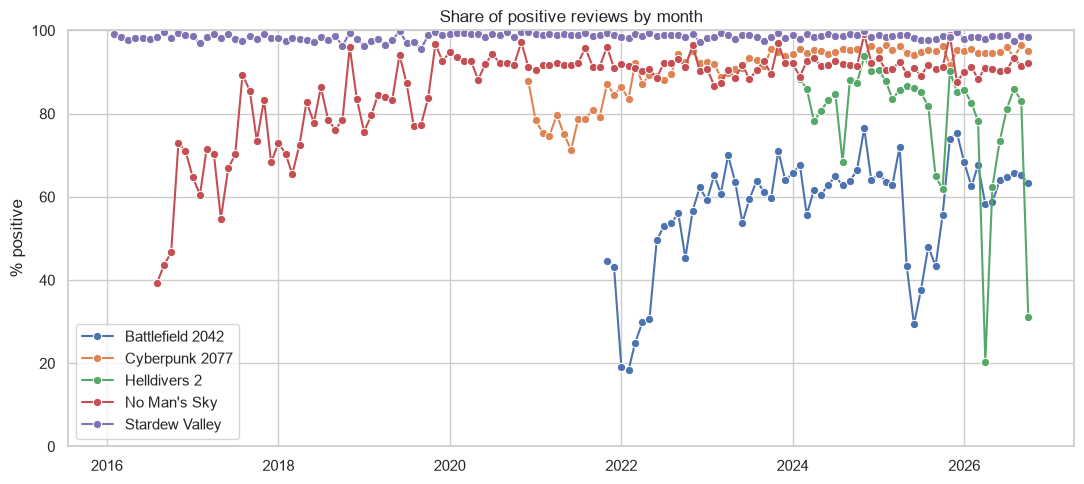

In [8]:
MIN_N = 30  # ignore months with too few reviews to be reliable
monthly = (df.groupby(["game", "month"])
             .agg(pct_positive=("recommended", "mean"), n=("recommended", "size"))
             .reset_index())
monthly = monthly[monthly["n"] >= MIN_N]
monthly["pct_positive"] *= 100

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly, x="month", y="pct_positive", hue="game", marker="o", ax=ax)
ax.set(title="Share of positive reviews by month", xlabel="", ylabel="% positive", ylim=(0, 100))
ax.legend(title="")
fig.tight_layout()
fig.savefig(IMG / "positive_share_by_month.png", dpi=150)
plt.show()

### Review volume over time (after the monthly cap)

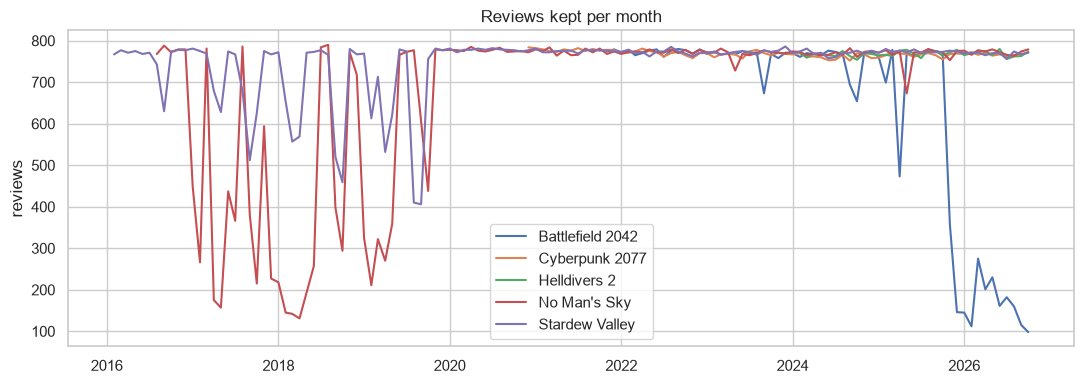

In [9]:
vol = df.groupby(["game", "month"]).size().rename("reviews").reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=vol, x="month", y="reviews", hue="game", ax=ax)
ax.set(title="Reviews kept per month", xlabel="", ylabel="reviews")
ax.legend(title="")
fig.tight_layout()
fig.savefig(IMG / "reviews_per_month.png", dpi=150)
plt.show()

### Does playtime change how positive people are?

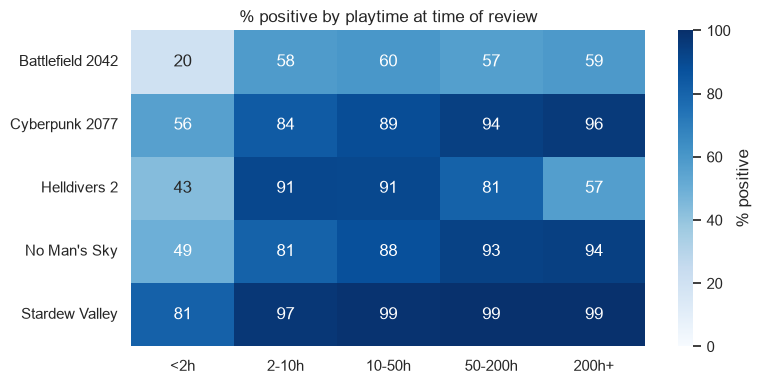

In [10]:
pt = (df.dropna(subset=["playtime_bucket"])
        .pivot_table(index="game", columns="playtime_bucket", values="recommended",
                     aggfunc="mean", observed=True) * 100)

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pt, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "% positive"})
ax.set(title="% positive by playtime at time of review", xlabel="", ylabel="")
fig.tight_layout()
fig.savefig(IMG / "positive_by_playtime.png", dpi=150)
plt.show()

### Review length: positive vs negative

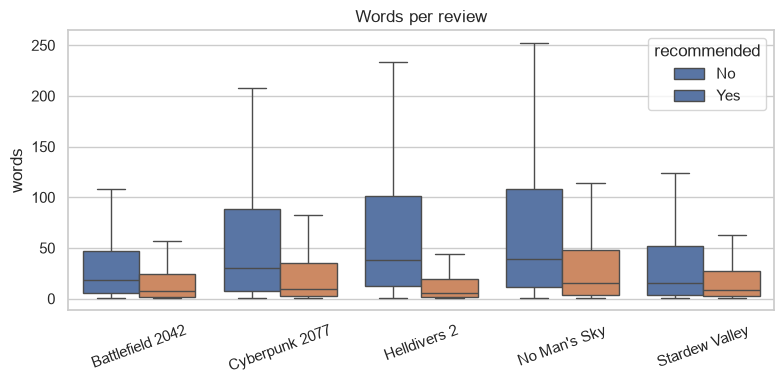

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="game", y="word_count", hue="recommended", showfliers=False, ax=ax)
ax.set(title="Words per review", xlabel="", ylabel="words")
ax.legend(title="recommended", labels=["No", "Yes"])
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig(IMG / "review_length.png", dpi=150)
plt.show()